In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
import re

base_url = "https://books.toscrape.com/catalogue/page-{}.html"
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
books_data = []

for page_num in range(1, 51):
    url = base_url.format(page_num)
    response = requests.get(url)
    soup = BeautifulSoup(response.text, 'html.parser')

    articles = soup.find_all('article', class_='product_pod')

    for article in articles:
        title = article.h3.a['title']
        price_text = article.find('p', class_='price_color').text.strip()
        price = float(re.sub(r'[^0-9.]', '', price_text))
        rating_class = article.find('p', class_='star-rating')['class']
        rating_word = [c for c in rating_class if c != 'star-rating'][0]
        rating = rating_map.get(rating_word, 0)
        stock_text = article.find('p', class_='instock availability').text.strip()
        quantity_match = re.search(r'\((\d+) available\)', stock_text)
        quantity = int(quantity_match.group(1)) if quantity_match else 0
        in_stock = "In stock" in stock_text

        books_data.append({
            'Title': title,
            'Price': price,
            'Rating': rating,
            'In_Stock': in_stock,
            'Quantity': quantity
        })

    time.sleep(0.5)
    print(f"Scraped page {page_num}")

df = pd.DataFrame(books_data)
print(f"Total books scraped: {len(df)}")
print(df.head())

Scraped page 1
Scraped page 2
Scraped page 3
Scraped page 4
Scraped page 5
Scraped page 6
Scraped page 7
Scraped page 8
Scraped page 9
Scraped page 10
Scraped page 11
Scraped page 12
Scraped page 13
Scraped page 14
Scraped page 15
Scraped page 16
Scraped page 17
Scraped page 18
Scraped page 19
Scraped page 20
Scraped page 21
Scraped page 22
Scraped page 23
Scraped page 24
Scraped page 25
Scraped page 26
Scraped page 27
Scraped page 28
Scraped page 29
Scraped page 30
Scraped page 31
Scraped page 32
Scraped page 33
Scraped page 34
Scraped page 35
Scraped page 36
Scraped page 37
Scraped page 38
Scraped page 39
Scraped page 40
Scraped page 41
Scraped page 42
Scraped page 43
Scraped page 44
Scraped page 45
Scraped page 46
Scraped page 47
Scraped page 48
Scraped page 49
Scraped page 50
Total books scraped: 1000
                                   Title  Price  Rating  In_Stock  Quantity
0                   A Light in the Attic  51.77       3      True         0
1                     Tipping t

In [5]:
df.to_csv("raw_books_data.csv", index=False)
print("Raw data saved successfully as raw_books_data.csv")

Raw data saved successfully as raw_books_data.csv


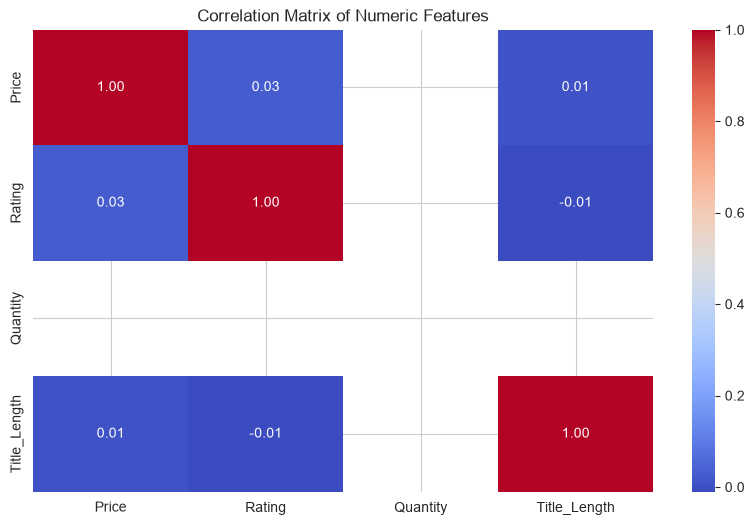

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'Title_Length' not in df.columns:
    df['Title_Length'] = df['Title'].str.len()

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.figure()
corr = df[['Price', 'Rating', 'Quantity', 'Title_Length']].corr() # This should now work
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numeric Features')
plt.show()

In [8]:
df = pd.read_csv("raw_books_data.csv")
print("Missing values before cleaning:")
print(df.isnull().sum())

df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Price'] = df['Price'].fillna(df['Price'].median())
df['Rating'] = df['Rating'].fillna(df['Rating'].median())
df['Quantity'] = df['Quantity'].fillna(0)
df['In_Stock_Binary'] = df['In_Stock'].astype(int)
df['Title_Length'] = df['Title'].str.len()
df = df.drop_duplicates(subset=['Title'], keep='first')

print(f"Clean dataset shape: {df.shape}")
print(df.info())
print(df.describe())

Missing values before cleaning:
Title       0
Price       0
Rating      0
In_Stock    0
Quantity    0
dtype: int64
Clean dataset shape: (999, 7)
<class 'pandas.DataFrame'>
Index: 999 entries, 0 to 999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            999 non-null    str    
 1   Price            999 non-null    float64
 2   Rating           999 non-null    int64  
 3   In_Stock         999 non-null    bool   
 4   Quantity         999 non-null    int64  
 5   In_Stock_Binary  999 non-null    int64  
 6   Title_Length     999 non-null    int64  
dtypes: bool(1), float64(1), int64(4), str(1)
memory usage: 55.6 KB
None
            Price      Rating  Quantity  In_Stock_Binary  Title_Length
count  999.000000  999.000000     999.0            999.0    999.000000
mean    35.073123    2.920921       0.0              1.0     39.136136
std     14.453659    1.434178       0.0              0.0     25.790

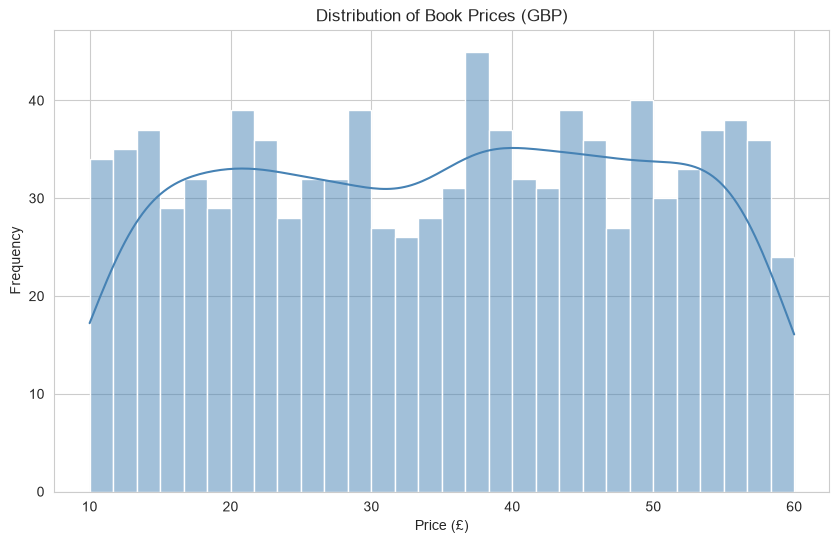

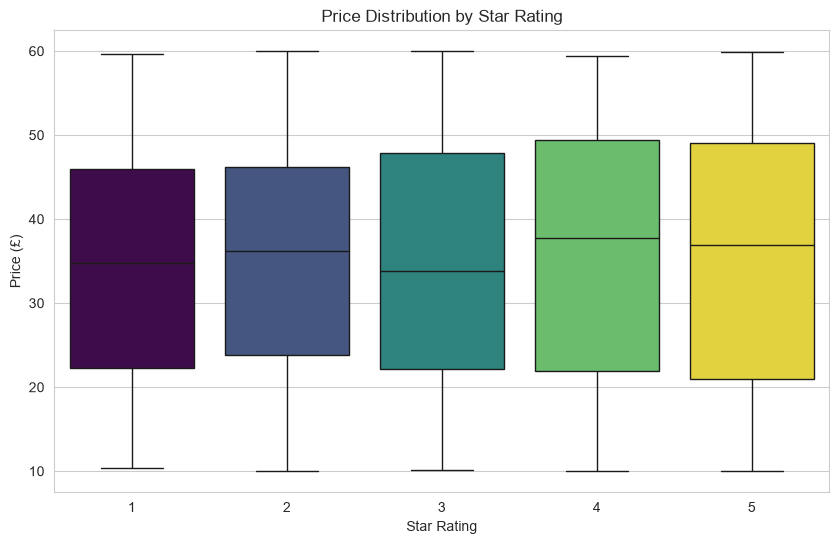

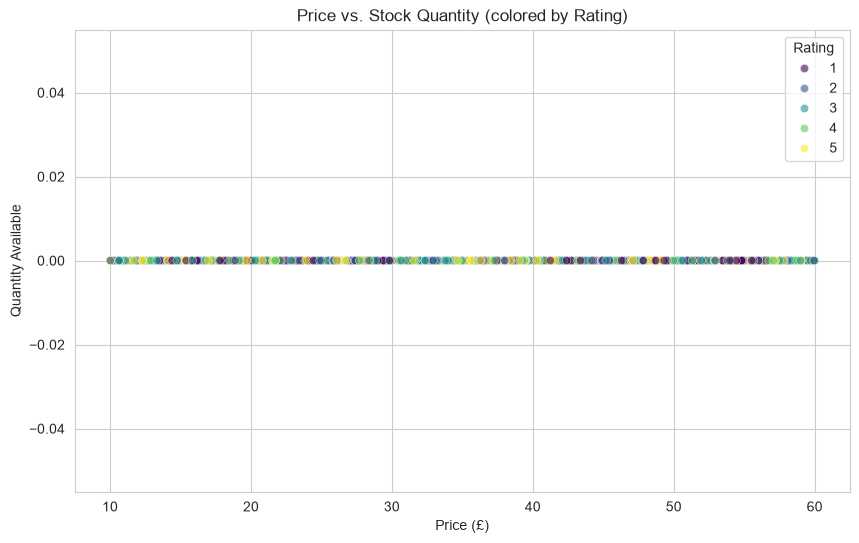

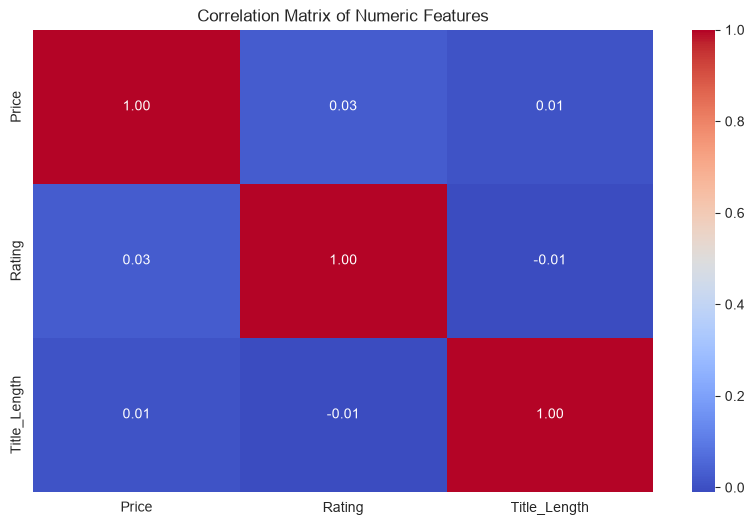

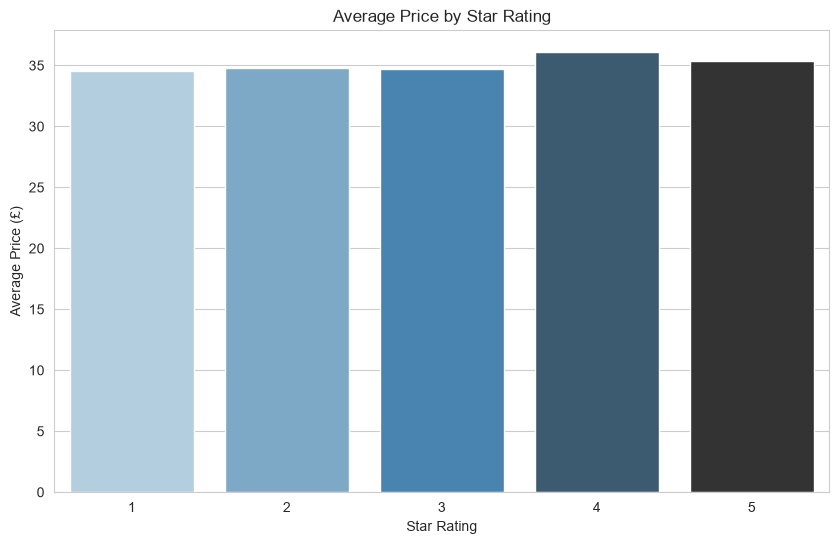

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.figure()
sns.histplot(df['Price'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of Book Prices (GBP)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()
plt.figure()

sns.boxplot(x='Rating', y='Price', data=df, hue='Rating', palette='viridis', legend=False)
plt.title('Price Distribution by Star Rating')
plt.xlabel('Star Rating')
plt.ylabel('Price (£)')
plt.show()
plt.figure()
sns.scatterplot(x='Price', y='Quantity', data=df, alpha=0.6, hue='Rating', palette='viridis')
plt.title('Price vs. Stock Quantity (colored by Rating)')
plt.xlabel('Price (£)')
plt.ylabel('Quantity Available')
plt.show()
plt.figure()
corr = df[['Price', 'Rating', 'Quantity', 'Title_Length']].corr()
corr = corr.dropna(axis=0, how='all').dropna(axis=1, how='all')
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numeric Features')
plt.show()

avg_price = df.groupby('Rating')['Price'].mean().reset_index()
plt.figure()
sns.barplot(x='Rating', y='Price', data=avg_price, hue='Rating', palette='Blues_d', legend=False)
plt.title('Average Price by Star Rating')
plt.xlabel('Star Rating')
plt.ylabel('Average Price (£)')
plt.show()

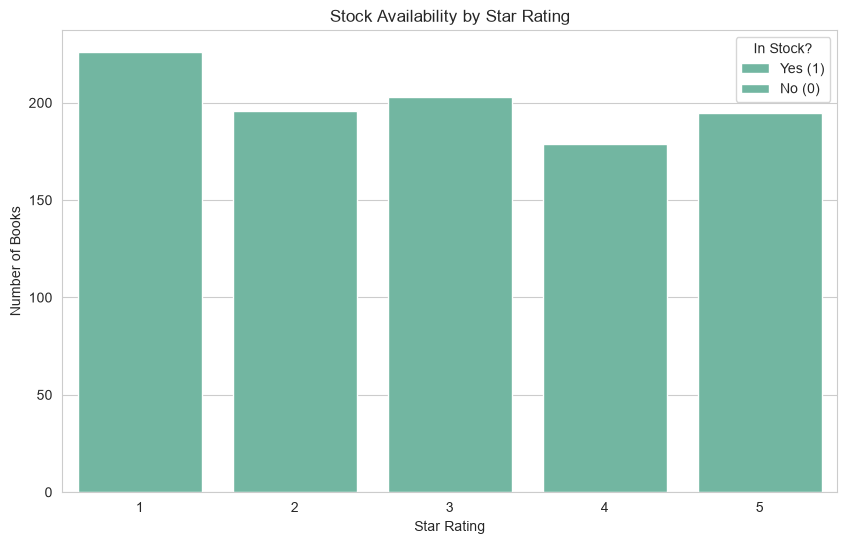

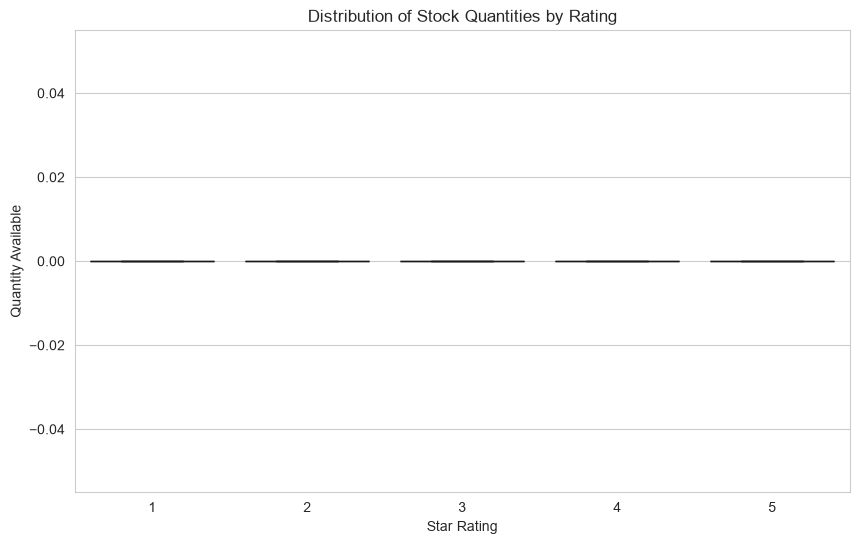

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.figure()
sns.countplot(x='Rating', hue='In_Stock_Binary', data=df, palette='Set2', color='blue')

plt.title('Stock Availability by Star Rating')
plt.xlabel('Star Rating')
plt.ylabel('Number of Books')
plt.legend(title='In Stock?', labels=['Yes (1)', 'No (0)'])
plt.show()


plt.figure()
sns.boxplot(x='Rating', y='Quantity', data=df, hue='Rating', palette='viridis', legend=False)
plt.title('Distribution of Stock Quantities by Rating')
plt.xlabel('Star Rating')
plt.ylabel('Quantity Available')
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

features = ['Rating', 'Quantity', 'In_Stock_Binary', 'Title_Length']
X = df[features]
y = df['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation ---")
print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")

coeff_df = pd.DataFrame({'Feature': features, 'Coefficient': model.coef_})
print("\n--- Feature Coefficients ---")
print(coeff_df)
print(f"Intercept: {model.intercept_:.2f}")

--- Model Evaluation ---
Mean Absolute Error (MAE): £12.29
Root Mean Squared Error (RMSE): £14.27
R-squared (R²): -0.0187

--- Feature Coefficients ---
           Feature  Coefficient
0           Rating     0.393760
1         Quantity     0.000000
2  In_Stock_Binary     0.000000
3     Title_Length     0.023322
Intercept: 33.19


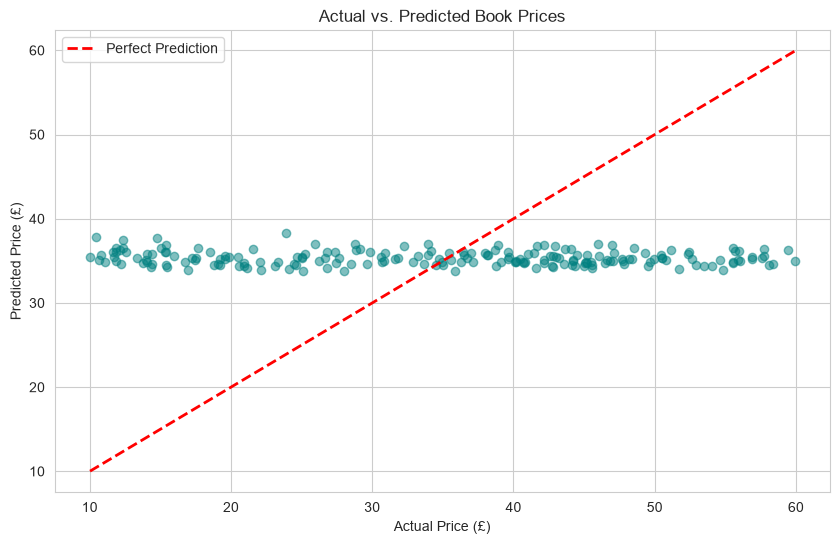

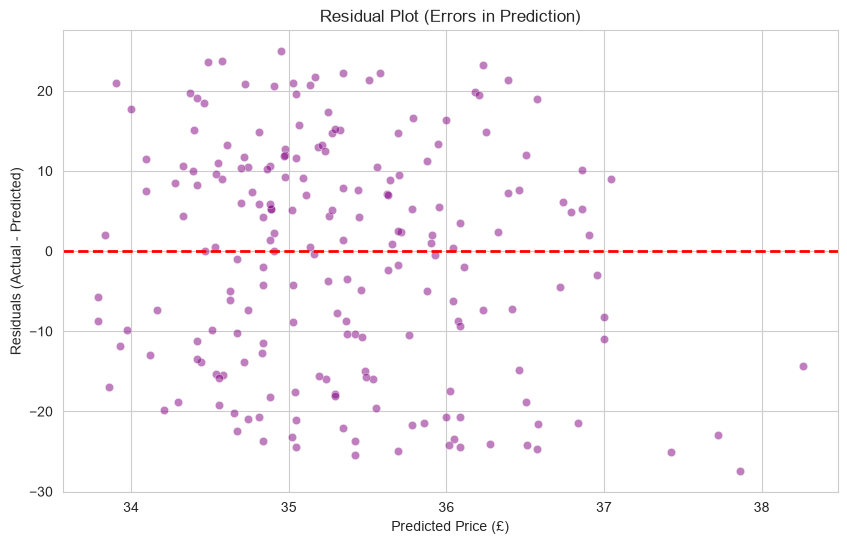

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.figure()
plt.scatter(y_test, y_pred, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
plt.title('Actual vs. Predicted Book Prices')
plt.xlabel('Actual Price (£)')
plt.ylabel('Predicted Price (£)')
plt.legend()
plt.show()

residuals = y_test - y_pred
plt.figure()
sns.scatterplot(x=y_pred, y=residuals, alpha=0.5, color='purple')
plt.axhline(y=0, color='red', linestyle='--', lw=2)
plt.title('Residual Plot (Errors in Prediction)')
plt.xlabel('Predicted Price (£)')
plt.ylabel('Residuals (Actual - Predicted)')
plt.show()

This project aims to grasp the influence factors of the prices and ratings of books in the website named “Books to Scrape”, as a Junior Data Scientist of a publishing analytics team. Collecting actual structured data, we can study catalogue trends on various genres and rating levels.

This is a report detailing an end-to-end data science workflow from web scraping, to data cleaning, exploratory data analysis (EDA), to develop a linear regression model to predict book prices. The learnings from the insights will enable retailers and publishers to fine-tune their catalogue offers and pricing.